# Alakoro FiberSense — Demo do Módulo MSE
### Monitoramento da Saúde Estrutural de edifícios antigos com DFOS multimodal (DTS + DSS + DAS)

**Motivação.** A aplicação combinada de fibra óptica distribuída — temperatura (DTS),
deformação Brillouin (DSS) e acústica distribuída (DAS) — ao patrimônio histórico
construído em alvenaria é uma **lacuna na literatura**: os estudos clássicos tratam
cada modalidade isoladamente, em poços de petróleo ou em estruturas modernas de
concreto/aço. Este módulo fecha essa lacuna simulando, de forma fisicamente
coerente e na **mesma posição**, as três assinaturas de uma fissura ativa.

**Cenário:** ruína de uma igreja barroca colonial (séc. XVIII) monitorada por uma
única fibra que percorre a fachada sul, a nave e a torre sineira
(`examples/mse_cenario.lua`).

**Referências:**
- **Owczarek (2021)** — difusividade térmica da alvenaria α ≈ 5×10⁻⁷ m²/s
  (penetração diária δ ≈ 0,117 m; anual δ ≈ 2,24 m);
- **Glisic & Inaudi (2012)** — fissura ativa = pico localizado de 3500–5000 µε
  (0,35–0,5 mm sobre comprimento de transferência L_t ≈ 10 cm) no DSS;
- **Hubbard (2021)** — cross-sensibilidade Brillouin ≈ 20 µε/°C e monitoramento
  modal de estruturas históricas;
- **Di Gennaro (2025)** — emissão acústica (AE) para monitoramento de fissuras
  em alvenaria.

In [1]:
from alakoro.mse import (
    carrega_cenario_lua, constroi_geometria, constroi_aquisicao,
    GeradorAssinaturasMSE, aplica_cenario,
)

# Cena declarada em Lua: geometria, exposição solar, material, fissuras e aquisição
cenario = carrega_cenario_lua("examples/mse_cenario.lua")
print(cenario["nome"])
print("fissuras:", [(f["posicao_m"], f["largura_mm"], f["atividade"])
                     for f in cenario["fissuras"]])

geometria = constroi_geometria(cenario["geometria"])
acq = constroi_aquisicao(cenario["aquisicao"])
gerador = GeradorAssinaturasMSE(geometria, acq, seed=42)

# Janela DAS mais curta para a demo (a campanha completa a 1 kHz geraria 100+ GB)
cenario["gerador"]["duracao_janela_das_s"] = 10.0
resultado = aplica_cenario(gerador, cenario)   # cenário fissura multimodal
for chave in ("dts", "dss", "das"):
    print(chave, resultado[chave].shape, "  signature:", resultado["signature_type"].code)

Ruína de Igreja Colonial — demonstração
fissuras: [(32.0, 0.4, 'ativa'), (71.5, 0.15, 'estavel')]
dts (1440, 400)   signature: cenario_fissura_multimodal
dss (1440, 400)   signature: cenario_fissura_multimodal
das (10000, 400)   signature: cenario_fissura_multimodal


## 1. Assinaturas multimodais lado a lado

A mesma fissura ativa (32,0 m na fachada sul) deixa rastros em todas as modalidades:
ponte térmica persistente no **DTS**, pico de ~4000 µε no **DSS** e eventos
impulsivos 50–500 Hz com degraus permanentes no **DAS**.

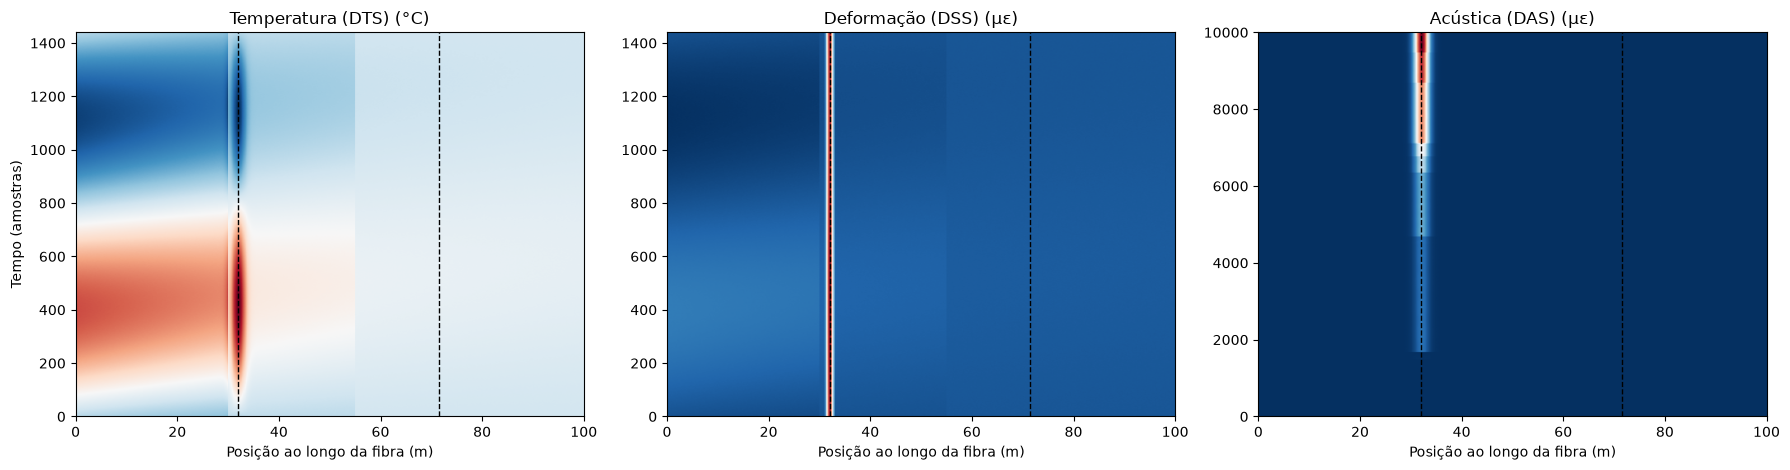

In [2]:
import matplotlib.pyplot as plt

fig, eixos = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, (chave, titulo, unidade) in zip(eixos, [
    ("dts", "Temperatura (DTS)", "°C"),
    ("dss", "Deformação (DSS)", "µε"),
    ("das", "Acústica (DAS)", "µε"),
]):
    dados = resultado[chave]
    ax.imshow(dados, aspect="auto", origin="lower", cmap="RdBu_r",
              extent=(0.0, geometria.comprimento_fibra_m, 0, dados.shape[0]))
    ax.set_title(f"{titulo} ({unidade})")
    ax.set_xlabel("Posição ao longo da fibra (m)")
    for f in cenario["fissuras"]:
        ax.axvline(f["posicao_m"], color="k", ls="--", lw=1)
eixos[0].set_ylabel("Tempo (amostras)")
plt.tight_layout()
plt.show()

## 2. Correção térmica do DSS (cross-sensibilidade Brillouin)

Todo traço DSS carrega um **strain aparente de ≈ 20 µε/°C** (cross-sensibilidade
Brillouin). Como o DTS mede a temperatura da própria fibra, o efeito pode ser
removido posição a posição: `corrige_temperatura_dss` subtrai 20 µε/°C do DSS,
deixando evidente o pico da fissura (residual típico de 2–20 µε).

Residual MAD após correção: 5.6 µε  (cross-sensibilidade 20 µε/°C)


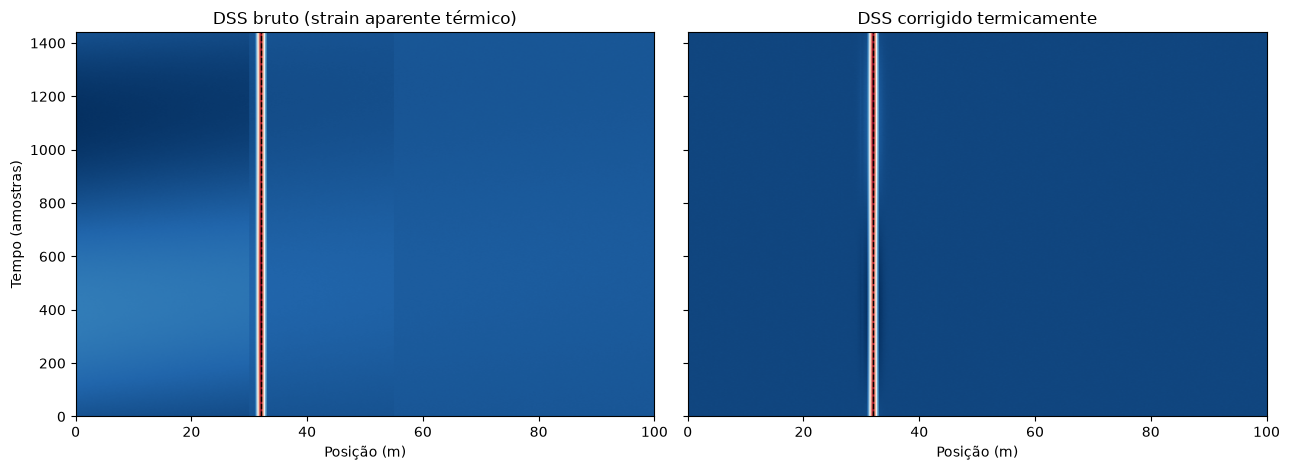

In [3]:
from alakoro.mse import MotorInferenciaMSE

motor = MotorInferenciaMSE(geometria=geometria, acq=acq)
dss_corrigido, residual_ue = motor.corrige_temperatura_dss(resultado["dss"], resultado["dts"])
print(f"Residual MAD após correção: {residual_ue:.1f} µε  (cross-sensibilidade 20 µε/°C)")

fig, eixos = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, dados, titulo in [
    (eixos[0], resultado["dss"], "DSS bruto (strain aparente térmico)"),
    (eixos[1], dss_corrigido, "DSS corrigido termicamente"),
]:
    ax.imshow(dados, aspect="auto", origin="lower", cmap="RdBu_r",
             extent=(0.0, geometria.comprimento_fibra_m, 0, dados.shape[0]))
    ax.set_title(titulo)
    ax.set_xlabel("Posição (m)")
    ax.axvline(32.0, color="k", ls="--", lw=1)
eixos[0].set_ylabel("Tempo (amostras)")
plt.tight_layout()
plt.show()

## 3. Inferência: do array ao evento semântico

O `MotorInferenciaMSE` aplica regras determinísticas — proeminência espacial
robusta (MAD) no DSS, envoltória de Hilbert + STA/LTA na banda 50–500 Hz no DAS,
offset térmico persistente no DTS — e emite eventos da ontologia com posição em
metros, confiança e severidade.

In [4]:
eventos = motor.inferir(
    dts=resultado["dts"], dss=resultado["dss"], das=resultado["das"],
    fs_das_hz=acq.fs_das_hz,
)
print(f"{len(eventos)} eventos emitidos:\n")
for ev in eventos:
    pos = getattr(ev, "posicao_m", getattr(ev, "posicao_fissura_m", None))
    print(f"  {type(ev).__name__:<30} posição = {pos:6.2f} m   confiança = {ev.confidence:.2f}   severidade = {ev.severity}")

3 eventos emitidos:

  PropagacaoFissuraEvento        posição =  32.33 m   confiança = 0.99   severidade = High
  EventoAcusticoFissura          posição =  32.08 m   confiança = 0.89   severidade = High
  AnomaliaTermicaEvento          posição =  32.08 m   confiança = 0.58   severidade = Medium


## 4. Ontologia: serialização em Turtle

As entidades do domínio MSE (estruturas, elementos, fissuras, instalações de
fibra) e os eventos detectados são serializadas em RDF/Turtle via `OntologyModel`.

In [5]:
from datetime import datetime
from alakoro.ontology import (
    OntologyModel, EdificioEclesiastico, Alvenaria, TorreSineira, Fissura, InstalacaoFibra,
)

igreja = EdificioEclesiastico(
    identifier="Igreja-Sao-Pedro-01", name="Igreja de São Pedro",
    localizacao="Pelourinho, Salvador/BA", ano_construcao=1750,
    estado_conservacao="ruina", estilo_arquitetonico="barroco",
)
fachada = Alvenaria(name="Alvenaria-Fachada-Sul", tipo_alvenaria="tijolo_macico",
                    material="tijolo maciço")
for f in cenario["fissuras"]:
    fachada.add_fissura(Fissura(name=f"Fissura-{f['posicao_m']:.1f}m", posicao_m=f["posicao_m"],
                                largura_mm=f["largura_mm"], tipo=f["tipo"], atividade=f["atividade"]))
igreja.add_elemento(fachada)
igreja.add_elemento(TorreSineira(name="Torre-Sineira", altura_m=22.0, n_sinos=2, material="pedra"))
igreja.add_instalacao(InstalacaoFibra(name="Fibra-MSE-01", comprimento_m=100.0, tecnica="colada",
                                      data_instalacao=datetime(2026, 3, 15)))

modelo = OntologyModel()
modelo.add(igreja)
for ev in eventos:                      # eventos detectados também entram no grafo
    modelo.add(ev)

turtle = modelo.to_turtle()
print(turtle[:1400])
print("...")

@prefix alakoro: <https://alakoro.fibersense/ontology#> .
@prefix owl: <http://www.w3.org/2002/07/owl#> .
@prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .

alakoro:452799dc-979e-4979-b180-ac37f485ab16 a alakoro:EventoAcusticoFissura ;
    alakoro:hasConfidence "0.8894954717232564"^^xsd:float ;
    alakoro:hasEnergia "173.64047259421633"^^xsd:float ;
    alakoro:hasEventType "CrackAcousticEmission" ;
    alakoro:hasIdentifier "452799dc-979e-4979-b180-ac37f485ab16" ;
    alakoro:hasName "Emissão Acústica de Fissura" ;
    alakoro:hasPosicaoM "32.08020050125313"^^xsd:float ;
    alakoro:hasSeverity "High" ;
    alakoro:hasTaxaEventosH "360.0"^^xsd:float .

alakoro:54705839-bb9a-4724-be7f-0cc40aa6dd2a a alakoro:AnomaliaTermicaEvento ;
    alakoro:hasConfidence "0.5817542312108289"^^xsd:float ;
    alakoro:hasEventType "ThermalAnomaly" ;
    alakoro:hasIdentifier "54705839-bb9a-4724-be7f-0cc40aa6dd2a" ;
    alakoro:hasName "Anomalia 